<a href="https://colab.research.google.com/github/ojaswi-raya/One-Look/blob/main/03_run_everything.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# One Look — Stage 3: run every experiment, then the demo

Run this after `01_setup_data.ipynb` (data on Google Drive). Run the cells **in order**.
It takes about 5–10 minutes. Everything is saved to `MyDrive/one-look/outputs/`.

What it does:
1. Labels every chip and makes the geographic split (test = Bolivia + Ghana).
2. Compares 4 approaches: MNDWI rule, logistic regression, small and large random forest.
3. Builds the UNKNOWN detector and tests it.
4. Measures model size and speed, and lists every wrong decision (failure analysis).
5. Demo on a test chip the model never saw, and on your own Sentinel-2 image.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/one-look/data/HandLabeled'
OUT  = '/content/drive/MyDrive/one-look'
%cd /content
!rm -rf One-Look && git clone -q https://github.com/ojaswi-raya/One-Look.git
%cd /content/One-Look
!pip -q install -r requirements.txt

Mounted at /content/drive
/content
/content/One-Look


## 1. Labels and geographic split

In [2]:
!python src/labels.py --root "$DATA" --out "$OUT/data/labels.csv"
!python src/split.py  --labels "$OUT/data/labels.csv" --out "$OUT/data/splits.json"

Skipping Ghana_234935: no valid pixels
Skipping Ghana_26376: no valid pixels
Skipping Ghana_277: no valid pixels
Skipping Ghana_5079: no valid pixels
Skipping Ghana_83483: no valid pixels
Saved 441 chips to /content/drive/MyDrive/one-look/data/labels.csv: 273 ALERT, 168 NO ALERT (threshold=1.0%)
train countries=['India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'USA'] | ALERT=197 | NO ALERT=109
val   countries=['Spain', 'Sri-Lanka'] | ALERT=46 | NO ALERT=26
test  countries=['Bolivia', 'Ghana'] | ALERT=30 | NO ALERT=33
Saved geographic split to /content/drive/MyDrive/one-look/data/splits.json


## 2–4. All experiments (approach comparison, UNKNOWN detector, size/speed, failures)

In [3]:
!python src/run_experiments.py --root "$DATA" --labels "$OUT/data/labels.csv" --splits "$OUT/data/splits.json" --out "$OUT/outputs"

Reading 441 chips ...
  100/441
  200/441
  skipping Paraguay_34417: almost no valid pixels
  300/441
  400/441
train: 305 chips, ALERT=196, NO ALERT=109
val  : 72 chips, ALERT=46, NO ALERT=26
test : 63 chips, ALERT=30, NO ALERT=33
Final model (chosen on validation): M2 Random forest small (50 trees, depth 6)

## Comparison of approaches (TEST = Bolivia, Ghana, never seen in training)

| Approach | Precision | Recall | F1 | False-alarm rate | ROC-AUC | Size (KB) | ms / chip (CPU) |
|---|---|---|---|---|---|---|---|
| B1 MNDWI rule (no learning) | 1.00 | 0.23 | 0.38 | 0.00 | 0.78 | 0 | 78.2 |
| M1 Logistic regression | 0.00 | 0.00 | 0.00 | 0.00 | 0.92 | 3 | 78.8 |
| M2 Random forest small (50 trees, depth 6) | 1.00 | 0.40 | 0.57 | 0.00 | 0.94 | 192 | 82.6 |
| M3 Random forest large (300 trees) | 1.00 | 0.40 | 0.57 | 0.00 | 0.94 | 1358 | 107.1 |

Thresholds chosen on validation (Spain, Sri-Lanka) to keep false alarms <= 5%. Final model chosen on validation: **M2 Random forest small (50 t

In [4]:
from IPython.display import Markdown, Image, display
import pandas as pd
display(Markdown(open(f'{OUT}/outputs/results.md').read()))

## Comparison of approaches (TEST = Bolivia, Ghana, never seen in training)

| Approach | Precision | Recall | F1 | False-alarm rate | ROC-AUC | Size (KB) | ms / chip (CPU) |
|---|---|---|---|---|---|---|---|
| B1 MNDWI rule (no learning) | 1.00 | 0.23 | 0.38 | 0.00 | 0.78 | 0 | 78.2 |
| M1 Logistic regression | 0.00 | 0.00 | 0.00 | 0.00 | 0.92 | 3 | 78.8 |
| M2 Random forest small (50 trees, depth 6) | 1.00 | 0.40 | 0.57 | 0.00 | 0.94 | 192 | 82.6 |
| M3 Random forest large (300 trees) | 1.00 | 0.40 | 0.57 | 0.00 | 0.94 | 1358 | 107.1 |

Thresholds chosen on validation (Spain, Sri-Lanka) to keep false alarms <= 5%. Final model chosen on validation: **M2 Random forest small (50 trees, depth 6)**. Full bundle (model + UNKNOWN detector): 218 KB, 82.3 ms per chip on CPU (feature extraction 78.2 ms).

## UNKNOWN detection

UNKNOWN if Mahalanobis distance > 159.9 (the 99.0% quantile on train+val).

| Scenes | n | Flagged UNKNOWN | AUROC vs real test chips |
|---|---|---|---|
| real test chips (in-distribution) | 63 | 0% | nan |
| synthetic: thick_cloud | 63 | 100% | 1.000 |
| synthetic: snow | 63 | 100% | 1.000 |
| synthetic: desert_sand | 63 | 100% | 1.000 |
| synthetic: sensor_noise | 63 | 100% | 1.000 |
| synthetic: dead_bands | 63 | 100% | 1.000 |

Synthetic scenes are test chips with simulated conditions, not real imagery.

## Three-way decisions on real test chips

| True \ Decision | ALERT | NO ALERT | UNKNOWN |
|---|---|---|---|
| ALERT | 12 | 18 | 0 |
| NO ALERT | 0 | 33 | 0 |

## Failure cases: 18 wrong test decisions (see failures.csv / failures.png)


### Failure analysis: every wrong decision on the test set

,chip_id,country,error,true_flood_fraction,alert_probability,permanent_water_fraction,unknown_score,clues
0,Bolivia_103757,Bolivia,MISSED FLOOD,0.4015,0.803,0.0000,72.4,no obvious clue - inspect image
1,Bolivia_129334,Bolivia,MISSED FLOOD,0.6419,0.783,0.0158,64.8,no obvious clue - inspect image
2,Bolivia_360519,Bolivia,MISSED FLOOD,0.0110,0.855,0.0000,6.4,small flood (<5% of chip)
3,Bolivia_379434,Bolivia,MISSED FLOOD,0.0412,0.760,0.0000,20.2,small flood (<5% of chip)
4,Ghana_1089161,Ghana,MISSED FLOOD,0.0123,0.297,0.0000,8.2,small flood (<5% of chip)
5,Ghana_135389,Ghana,MISSED FLOOD,0.0102,0.214,0.0000,16.8,small flood (<5% of chip)
6,Ghana_141910,Ghana,MISSED FLOOD,0.2630,0.753,0.0083,47.6,no obvious clue - inspect image
7,Ghana_147015,Ghana,MISSED FLOOD,0.0135,0.154,0.0000,11.7,small flood (<5% of chip)
8,Ghana_247288,Ghana,MISSED FLOOD,0.6151,0.863,0.0096,17.7,no obvious clue - inspect image
9,Ghana_308249,Ghana,MISSED FLOOD,0.0293,0.634,0.0014,6.8,small flood (<5% of chip)


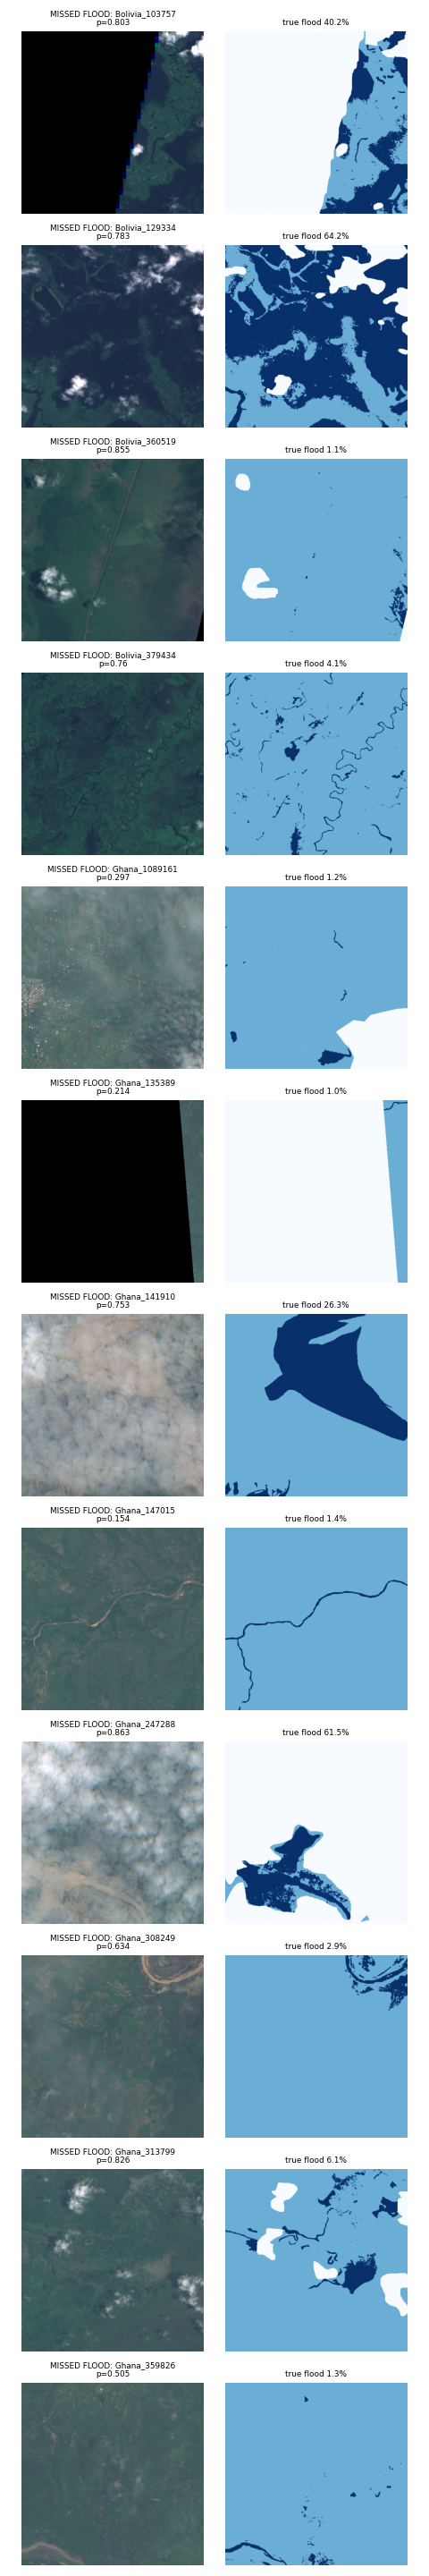

In [5]:
display(pd.read_csv(f'{OUT}/outputs/failures.csv'))
display(Image(f'{OUT}/outputs/failures.png'))

## 5. Demo on an image the model has never seen
First a Bolivia chip (test country, never used for training or tuning).

Image: /content/drive/MyDrive/one-look/data/HandLabeled/S2Hand/Bolivia_103757_S2Hand.tif  (512x512 px, 1 tile(s), 37 ms total)
  tile row     0 col     0: NO ALERT  p(flood)=0.80  unknown-score=72.4 (limit 159.9)
DECISION: NO ALERT
Picture saved to /content/drive/MyDrive/one-look/outputs/demo_test_chip.png


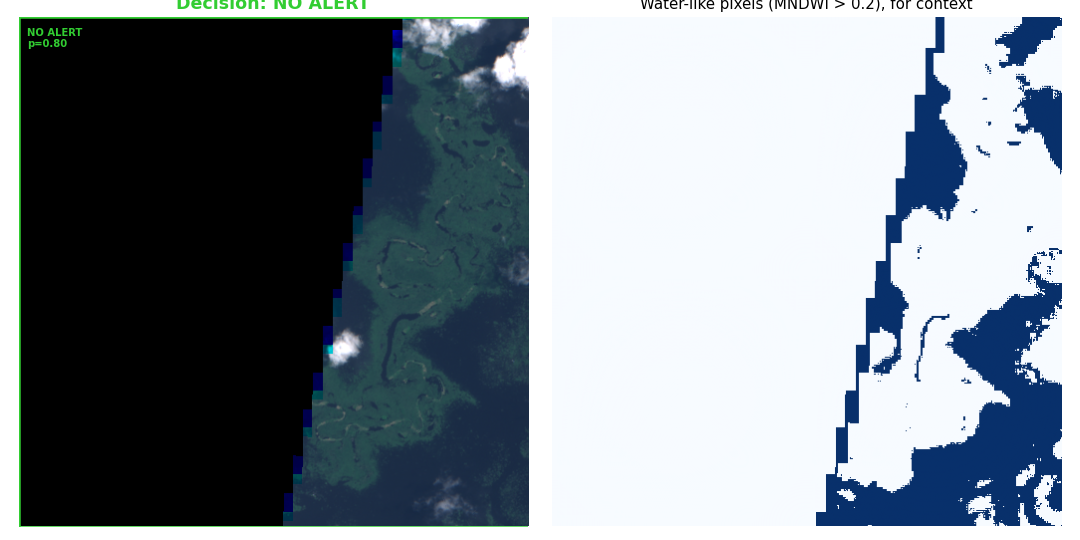

In [6]:
import glob, os
chip = sorted(glob.glob(f'{DATA}/S2Hand/Bolivia_*_S2Hand.tif'))[0]
!python src/predict.py --image "$chip" --model "$OUT/outputs/one_look_model.joblib" --out "$OUT/outputs/demo_test_chip.png"
display(Image(f'{OUT}/outputs/demo_test_chip.png'))

### Demo on your own new image
Upload a Sentinel-2 **L1C** GeoTIFF with all **13 bands** (B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B10, B11, B12)
at 10 m, downloaded from Copernicus Browser. Large scenes are cut into 512×512 tiles, one decision per tile.

In [7]:
from google.colab import files
up = files.upload()
for name in up:
    !python src/predict.py --image "$name" --model "$OUT/outputs/one_look_model.joblib" --out "$OUT/outputs/demo_{name}.png"
    display(Image(f'{OUT}/outputs/demo_{name}.png'))

## 6. Put the results in your GitHub repo
This downloads a zip of `outputs/`. Unzip it and upload the files into a `results/` folder of the repo
(GitHub → Add file → Upload files), then paste `results.md` into the README results section.

In [8]:
!cd "$OUT" && zip -qr /content/results.zip outputs
files.download('/content/results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>